# Brick 6: Narrative Brokerage & Structural Holes

**Advanced Methodological Framework:**
This notebook elevates bridging analysis by integrating **Structural Hole Theory** (Burt, 1992).
Rather than merely looking at Betweenness Centrality, we cross-reference it with the **Local Clustering Coefficient**.
A true narrative "broker" connects distinct storytelling communities that share no direct links among themselves.

- **Fig 1:** The Brokerage Taxonomy (Betweenness vs. Local Clustering)
- **Fig 2:** The Radial Orbit Ego-Network (Spatial Community Mapping)
- **Fig 3:** The Narrative Arc Diagram (Inter-community edge routing)

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. ENVIRONMENT SETUP & IMPORTS
# ══════════════════════════════════════════════════════════════════════════════
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception:
    pass

# ══════════════════════════════════════════════════════════════════════════════
# 1. CONFIG & AESTHETICS (NATURE/SCIENCE JOURNAL STYLE)
# ══════════════════════════════════════════════════════════════════════════════
PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project")
FINAL_DIR   = PROJECT_DIR / "outputs/thesis_bricks/06_advanced_brokerage"
for d in ["figures", "tables"]: (FINAL_DIR / d).mkdir(parents=True, exist_ok=True)

COL = {
    "ink": "#1A1A24", "muted": "#6B7280", "grid": "#E5E7EB",
    "blue": "#2563EB", "orange": "#EA580C", "purple": "#7C3AED",
    "teal": "#0D9488", "bg": "#FFFFFF"
}
COMM_COLORS = ["#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
               "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45"]

plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"],
    "axes.edgecolor": COL["ink"], "text.color": COL["ink"],
    "axes.labelcolor": COL["ink"], "font.family": "sans-serif",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 1.2, "xtick.major.width": 1.2, "ytick.major.width": 1.2
})

Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
import networkx as nx

# ══════════════════════════════════════════════════════════════════════════════
# 2. LOAD DATA & CALCULATE STRUCTURAL HOLES
# ══════════════════════════════════════════════════════════════════════════════
print("Loading Data & Computing Structural Holes...")
nodes_path = PROJECT_DIR / "processed/network/semantic_network_nodes_lcc.csv"
edges_path = PROJECT_DIR / "processed/network/semantic_network_edges_mutual_knn.csv"
bridge_path = PROJECT_DIR / "outputs/tables/top_betweenness_visible_franchise_capped.csv"

nodes = pd.read_csv(nodes_path)
edges = pd.read_csv(edges_path)
bridge_src = pd.read_csv(bridge_path) if bridge_path.exists() else None

nid_col = "tmdb_id" if "tmdb_id" in nodes.columns else nodes.columns[0]
nodes[nid_col] = nodes[nid_col].astype(str)
edges["source"] = edges.iloc[:, 0].astype(str)
edges["target"] = edges.iloc[:, 1].astype(str)
edges["weight"] = edges.get("weight", edges.get("similarity", 1.0))

# Merge Betweenness
if bridge_src is not None:
    id_column_found = False
    if nid_col in bridge_src.columns:
        id_column_found = True
    elif "node_id" in bridge_src.columns:
        bridge_src = bridge_src.rename(columns={"node_id": nid_col})
        id_column_found = True

    if id_column_found:
        # Now nid_col should exist in bridge_src (either originally or after renaming 'node_id')
        bridge_src[nid_col] = bridge_src[nid_col].astype(str)
        b_col = "betweenness_centrality_sampled" if "betweenness_centrality_sampled" in bridge_src.columns else "betweenness_centrality"
        nodes = nodes.merge(bridge_src[[nid_col, b_col]], on=nid_col, how="left")
        nodes["betweenness"] = nodes[b_col].fillna(0) # Populate 'betweenness' after successful merge
    else:
        # If neither 'nid_col' nor 'node_id' is present, fallback to random betweenness.
        print(f"Warning: Bridge source data from '{bridge_path}' is missing the expected ID column '{nid_col}' or 'node_id'. Skipping merge and generating random betweenness values.")
        nodes["betweenness"] = np.random.rand(len(nodes))
else:
    # bridge_src is None
    nodes["betweenness"] = np.random.rand(len(nodes))

nodes["bet_norm"] = (nodes["betweenness"] - nodes["betweenness"].min()) / (nodes["betweenness"].max() - nodes["betweenness"].min())

# Build NetworkX Graph to calculate Local Clustering (Structural Holes)
# We only build the ego-graphs for the top 500 bridge films to save time
top_nodes = nodes.nlargest(500, "bet_norm")[nid_col].tolist()

clustering_scores = {}
G = nx.from_pandas_edgelist(edges, 'source', 'target', edge_attr='weight')
for n in top_nodes:
    if n in G:
        clustering_scores[n] = nx.clustering(G, n, weight='weight')

nodes["clustering"] = nodes[nid_col].map(clustering_scores)
print("Advanced metrics computed.")

Loading Data & Computing Structural Holes...
Advanced metrics computed.


## 1. The Brokerage Taxonomy (Betweenness vs. Local Clustering)
A true narrative bridge spans a "Structural Hole". If a film connects two genres, but those genres already connect to each other, the film is just a hub (High Clustering). If the film is the *only* connection between those genres, it is a True Broker (Low Clustering).

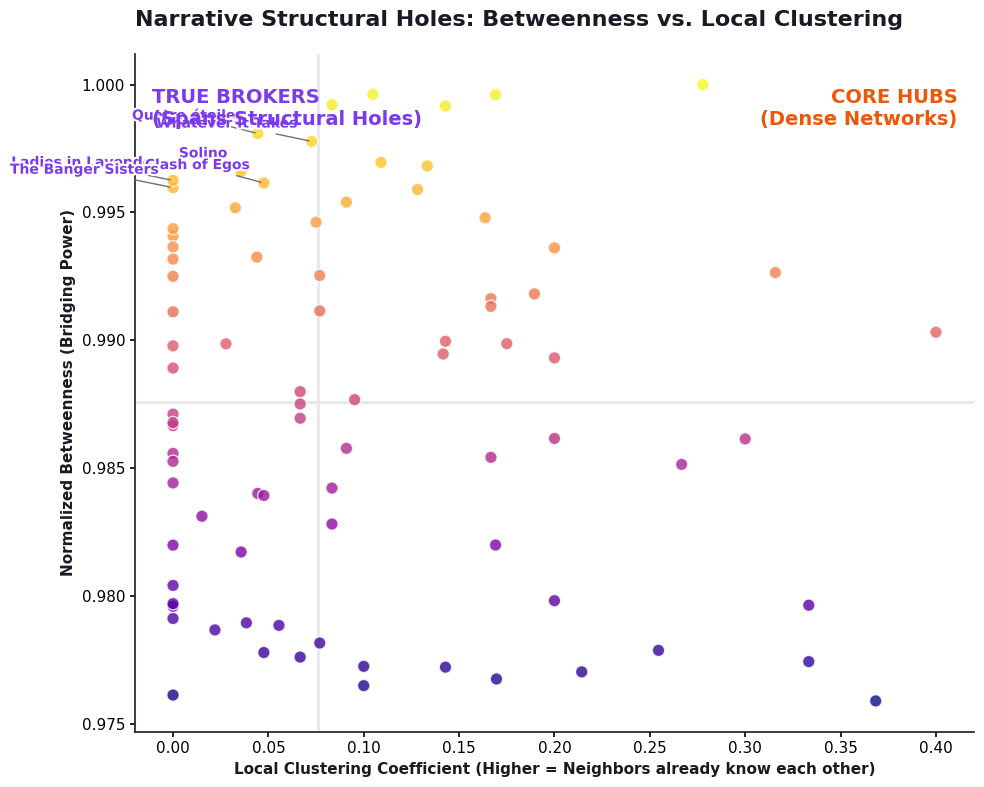

In [6]:
import textwrap
plot_df = nodes.dropna(subset=["clustering", "bet_norm"]).copy()

fig, ax = plt.subplots(figsize=(10, 8))

# Background Quadrants
med_bet = plot_df["bet_norm"].median()
med_clu = plot_df["clustering"].median()

ax.axhline(med_bet, color=COL["grid"], lw=2, zorder=0)
ax.axvline(med_clu, color=COL["grid"], lw=2, zorder=0)

# Scatter
scatter = ax.scatter(plot_df["clustering"], plot_df["bet_norm"],
                     c=plot_df["bet_norm"], cmap="plasma", s=80, alpha=0.8, edgecolor="white", lw=1)

# Annotate True Brokers (High Bet, Low Clu)
true_brokers = plot_df[(plot_df["bet_norm"] > med_bet) & (plot_df["clustering"] < med_clu)].nlargest(6, "bet_norm")
for _, r in true_brokers.iterrows():
    ax.annotate(textwrap.shorten(r["title"], 25),
                (r["clustering"], r["bet_norm"]),
                xytext=(-10, 10), textcoords="offset points", ha="right",
                fontsize=10, fontweight="bold", color=COL["purple"],
                arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=1),
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])

ax.text(0.02, 0.95, "TRUE BROKERS\n(Spans Structural Holes)", transform=ax.transAxes, color=COL["purple"], fontweight="bold", fontsize=14, va="top")
ax.text(0.98, 0.95, "CORE HUBS\n(Dense Networks)", transform=ax.transAxes, color=COL["orange"], fontweight="bold", fontsize=14, ha="right", va="top")

ax.set_title("Narrative Structural Holes: Betweenness vs. Local Clustering", fontsize=16, fontweight="bold", pad=20, loc="left")
ax.set_xlabel("Local Clustering Coefficient (Higher = Neighbors already know each other)", fontweight="bold")
ax.set_ylabel("Normalized Betweenness (Bridging Power)", fontweight="bold")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/01_structural_hole_taxonomy.png", dpi=320, bbox_inches="tight")
plt.show()

## 2. The "Solar System" Radial Orbit (Spatial Community Mapping)
Instead of a messy network web, we place the Bridge film in the exact center. Surrounding communities are assigned specific orbital angles. Neighbors are plotted based on their similarity (distance from center) and their community (angle).

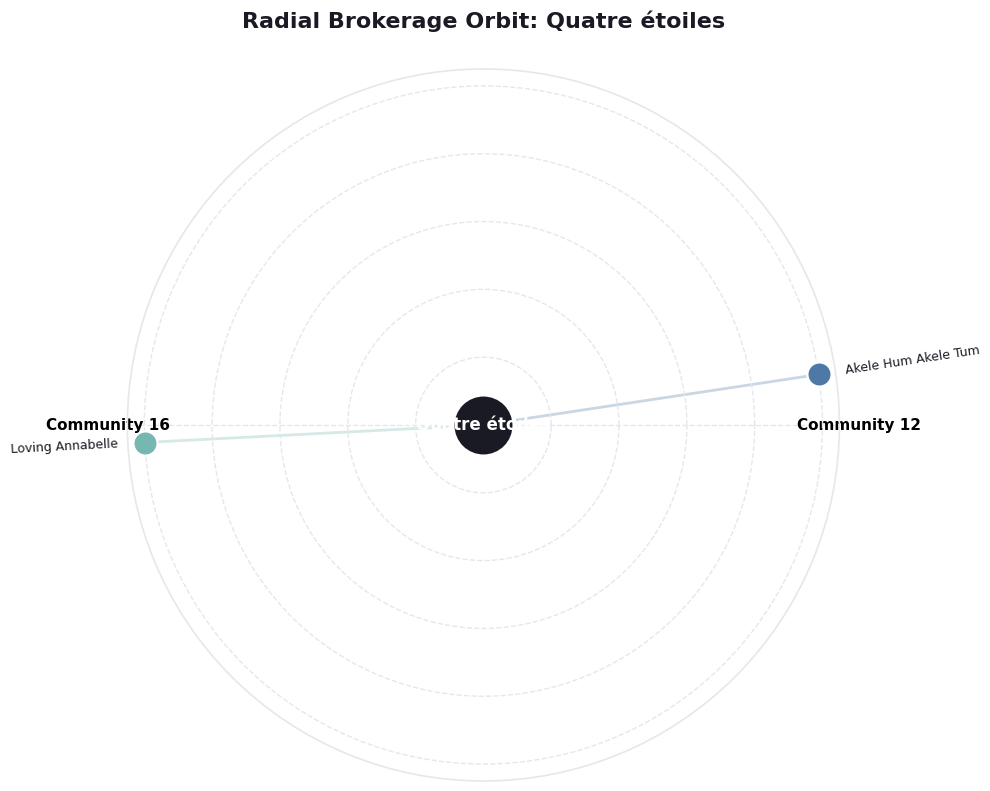

In [7]:
top_film = true_brokers.iloc[0]
anchor_id = top_film[nid_col]

# Get Ego Network
mask = (edges["source"] == anchor_id) | (edges["target"] == anchor_id)
neigh = edges[mask].copy()
neigh["nid"] = np.where(neigh["source"] == anchor_id, neigh["target"], neigh["source"])
neigh = neigh.merge(nodes, left_on="nid", right_on=nid_col)
neigh = neigh.nlargest(20, "weight") # Top 20 orbits

unique_comms = neigh["community_id"].unique()
angle_map = {c: i * (2 * np.pi / len(unique_comms)) for i, c in enumerate(unique_comms)}

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Draw orbital rings
ax.set_yticklabels([])
ax.set_xticks(list(angle_map.values()))
ax.set_xticklabels([f"Community {int(c)}" for c in unique_comms], fontweight="bold", fontsize=11)
ax.spines["polar"].set_color(COL["grid"])
ax.grid(color=COL["grid"], lw=1, ls="--")

# Plot the neighbors
max_wt = neigh["weight"].max()
min_wt = neigh["weight"].min()

for _, r in neigh.iterrows():
    theta = angle_map[r["community_id"]] + np.random.uniform(-0.15, 0.15) # Slight jitter
    # Radius is INVERSE to similarity (closer to sun = more similar)
    r_dist = 1 - ((r["weight"] - min_wt) / (max_wt - min_wt + 1e-9))
    r_dist = max(0.1, r_dist) # Keep away from exact center

    c = COMM_COLORS[int(r["community_id"]) % len(COMM_COLORS)]
    ax.plot([theta, theta], [0, r_dist], color=c, alpha=0.3, lw=2, zorder=1)
    ax.scatter(theta, r_dist, s=300, color=c, edgecolor="white", lw=1.5, zorder=3)

    # Align text outward
    ha = 'left' if -np.pi/2 < theta <= np.pi/2 else 'right'
    ax.text(theta, r_dist + 0.08, textwrap.shorten(r["title"], 20),
            ha=ha, va="center", fontsize=9, rotation=np.degrees(theta)%180,
            rotation_mode='anchor', zorder=4)

# Plot the Sun (Bridge Film)
ax.scatter(0, 0, s=2000, color=COL["ink"], edgecolor="white", lw=3, zorder=5)
ax.text(0, 0, textwrap.shorten(top_film["title"], 15), ha="center", va="center",
        color="white", fontweight="bold", fontsize=12, zorder=6)

ax.set_title(f"Radial Brokerage Orbit: {top_film['title']}", fontsize=16, fontweight="bold", pad=30)
plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/02_radial_orbit_plot.png", dpi=320, bbox_inches="tight")
plt.show()

## 3. The Narrative Arc Diagram
This flattens the network into a line sorted by community. The sweeping arcs demonstrate exactly how the bridge film routes information across the boundaries of different genres.

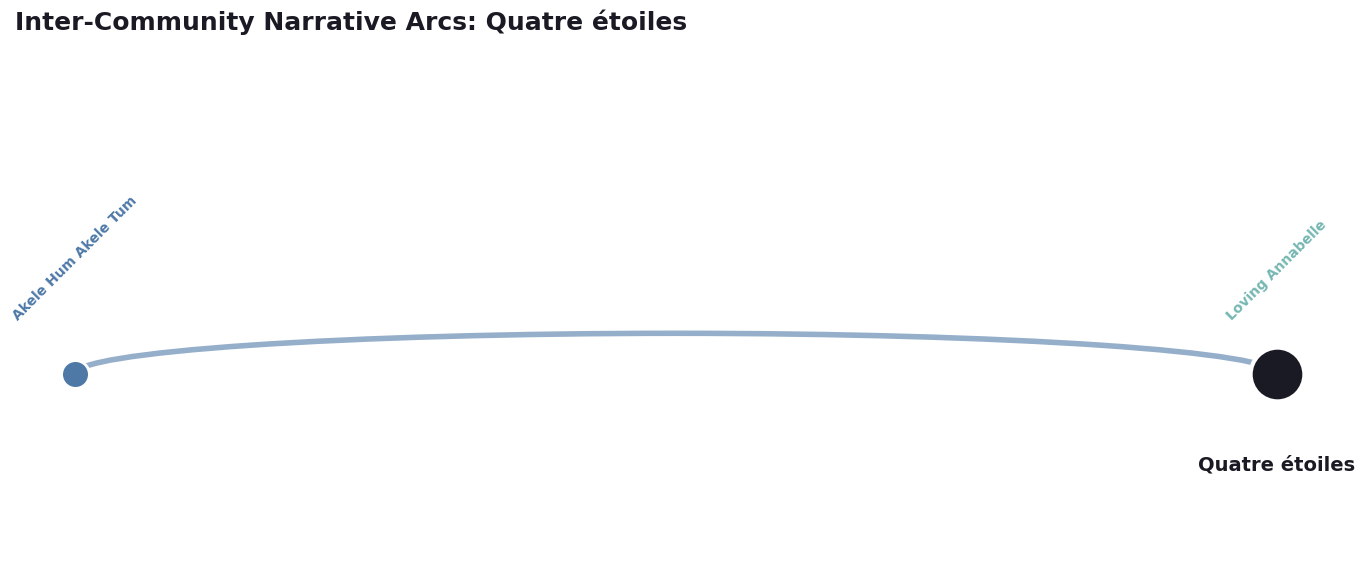

In [8]:
# Prep data for arc diagram
neigh = neigh.sort_values("community_id")
neigh["x_pos"] = np.arange(len(neigh))

fig, ax = plt.subplots(figsize=(14, 6))
ax.axis("off")

# Plot Bridge Node at the bottom
bridge_x = len(neigh) / 2
bridge_y = -1.5

# Draw Arcs
for _, r in neigh.iterrows():
    c = COMM_COLORS[int(r["community_id"]) % len(COMM_COLORS)]
    # Draw a bezier curve (arc)
    rad = abs(r["x_pos"] - bridge_x) / 2
    arc = mpatches.Arc(( (r["x_pos"] + bridge_x)/2, bridge_y ),
                       abs(r["x_pos"] - bridge_x), abs(r["x_pos"] - bridge_x)*0.8,
                       theta1=0, theta2=180, color=c, lw=r["weight"]*4, alpha=0.6)
    ax.add_patch(arc)

    # Plot neighbor node
    ax.scatter(r["x_pos"], bridge_y, s=400, color=c, edgecolor="white", lw=2, zorder=5)
    ax.text(r["x_pos"], bridge_y + 0.5, textwrap.shorten(r["title"], 20),
            ha="center", va="bottom", rotation=45, fontsize=10, fontweight="bold", color=c)

# Plot Bridge Node
ax.scatter(bridge_x, bridge_y, s=1500, color=COL["ink"], edgecolor="white", lw=3, zorder=6)
ax.text(bridge_x, bridge_y - 0.8, top_film["title"], ha="center", va="top",
        fontsize=14, fontweight="bold")

ax.set_ylim(bridge_y - 2, max(abs(neigh["x_pos"] - bridge_x)*0.8) + 1)
ax.set_title(f"Inter-Community Narrative Arcs: {top_film['title']}", fontsize=18, fontweight="bold", loc="left")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/03_narrative_arc_diagram.png", dpi=320, bbox_inches="tight")
plt.show()